# ANN, RNN, and LSTM for RUL Prediction

This combined notebook trains and evaluates an ANN and two recurrent models (RNN and LSTM) for Remaining Useful Life prediction. It uses a consistent engine-level train/validation/test split. Each model saves its best validation-loss checkpoint, and the final section compares the models on common held-out validation engine-cycles and saves the best overall model.

Run code cells from top to bottom. Training cells can take several minutes.

## ANN model

In [1]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

%matplotlib inline

In [2]:
# Load and Prepare Data
base_dir = Path.cwd().resolve()
if not (base_dir / "Data").exists():
    base_dir = base_dir.parent

csv_path = (base_dir / "Data" / "Turbofan_Engine_Degradation_Dataset.csv").resolve()
df = pd.read_csv(csv_path)

df = df.sort_values(['engine_id', 'cycle']).drop_duplicates().reset_index(drop=True)

feature_columns = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col not in ['engine_id', 'RUL']
]
for col in feature_columns:
    df[col] = df[col].fillna(df[col].median())

X = df[feature_columns].copy()
y = df['RUL'].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)
X.head()

Features shape: (61249, 25)
Target shape: (61249,)


,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,5.70,...,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670
1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,13.61,...,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552
2,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,5.69,...,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213
3,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,5.70,...,129.80,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176
4,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,9.00,...,164.11,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754


In [3]:
# Train/Test Split
# Use the exact engine-level split used by the RNN/LSTM notebook.
engines = sorted(df['engine_id'].unique())
train_engines, temp_engines = train_test_split(engines, test_size=0.3, random_state=42)
val_engines, test_engines = train_test_split(temp_engines, test_size=0.5, random_state=42)

train_mask = df['engine_id'].isin(train_engines)
val_mask = df['engine_id'].isin(val_engines)
test_mask = df['engine_id'].isin(test_engines)
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_val, y_val = X.loc[val_mask], y.loc[val_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]

# Scale features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Test shape:", X_test_scaled.shape)
print("Train target stats:", y_train.describe().to_dict())

Train shape: (42834, 25)
Validation shape: (9102, 25)
Test shape: (9313, 25)
Train target stats: {'count': 42834.0, 'mean': 131.7046505112761, 'std': 86.52061671123916, 'min': 0.0, '25%': 61.0, '50%': 123.0, '75%': 189.0, 'max': 445.0}


In [4]:
# Build ANN Model
model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.1),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,697 (53.50 KB)

 Trainable params: 13,697 (53.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 7915.5459 - mae: 67.4339
Epoch 1: val_loss improved from None to 4627.87402, saving model to D:\Guvi\Ferro Vision\models\ann_best.keras

Epoch 1: finished saving model to D:\Guvi\Ferro Vision\models\ann_best.keras
335/335 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 7915.5459 - mae: 67.4339 - val_loss: 4627.8740 - val_mae: 52.1789
Epoch 2/20
300/335 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3600.6025 - mae: 47.8224
Epoch 2: val_loss improved from 4627.87402 to 4023.91772, saving model to D:\Guvi\Ferro Vision\models\ann_best.keras

Epoch 2: finished saving model to D:\Guvi\Ferro Vision\models\ann_best.keras
335/335 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 3559.0029 - mae: 47.5275 - val_loss: 4023.9177 - val_mae: 48.7388
Epoch 3/20
327/335 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3156.8010 - mae: 44.2330
Epoch 3: val_loss improved from 4023.91772 to 3413.72778, saving model to D:\Guvi\Ferro Vision\models\ann_best.keras

Epoch 3: fini

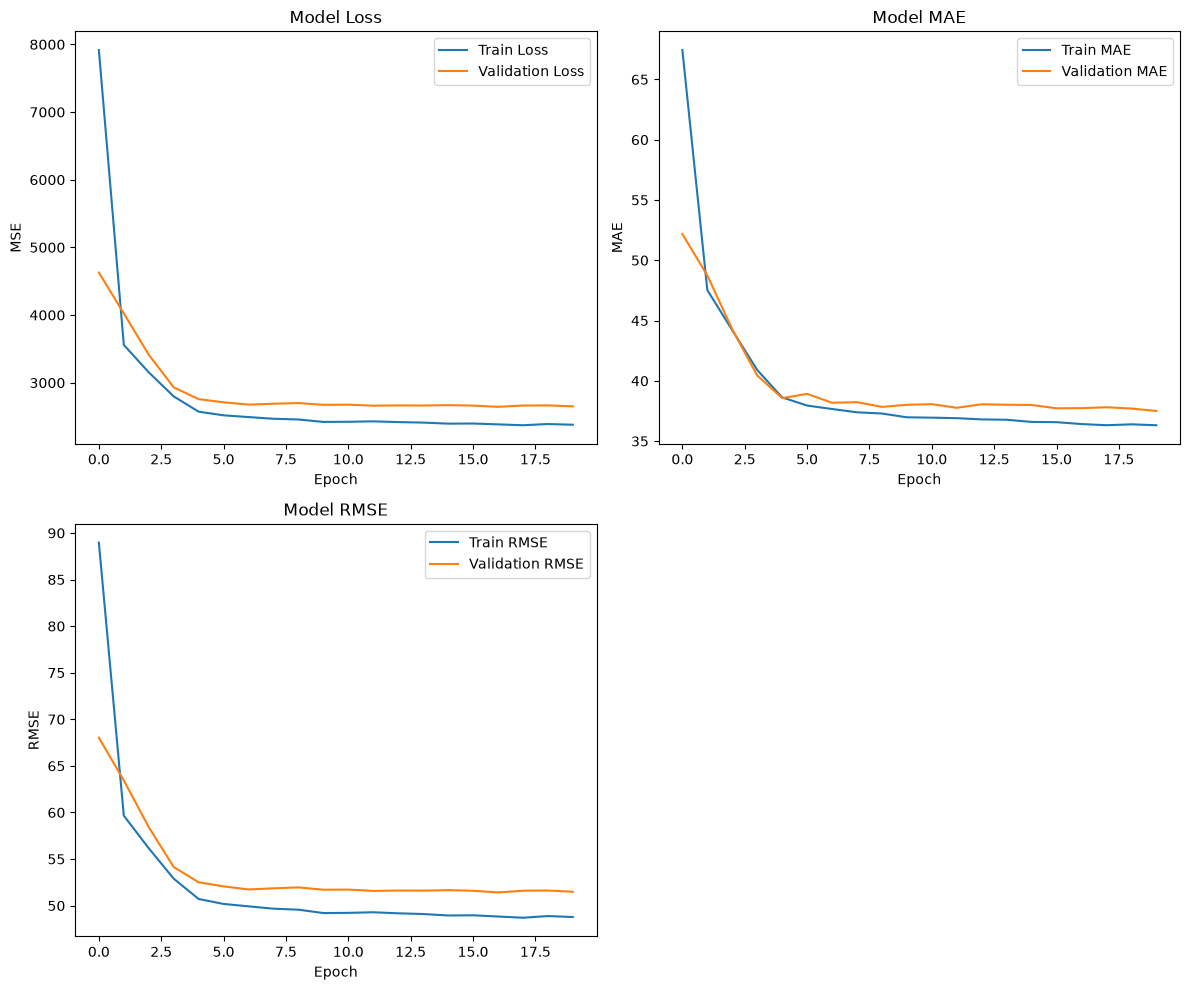

In [5]:
# Save the checkpoint with the lowest validation loss.
ann_model_path = base_dir / "models" / "ann_best.keras"
ann_model_path.parent.mkdir(parents=True, exist_ok=True)
ann_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=ann_model_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=True,
    ),
]

# Train the Model
history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=20,
    batch_size=128,
    verbose=1,
    callbacks=ann_callbacks,
)

# Continue evaluation with the best saved checkpoint.
model = keras.models.load_model(ann_model_path)
print(f"Best ANN checkpoint saved to: {ann_model_path}")
print(f"Best validation loss: {min(history.history['val_loss']):.4f}")

# Save the feature scaler and exact column order required for inference.
ann_preprocessing_path = base_dir / "models" / "ann_preprocessing.joblib"
joblib.dump(
    {"scaler": scaler, "feature_columns": feature_columns},
    ann_preprocessing_path,
)
print(f"ANN preprocessing saved to: {ann_preprocessing_path}")

# Compute RMSE from MSE for training/validation history
history.history['rmse'] = [np.sqrt(x) for x in history.history['loss']]
history.history['val_rmse'] = [np.sqrt(x) for x in history.history['val_loss']]

# Plot training history
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Model MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history.history['rmse'], label='Train RMSE')
plt.plot(history.history['val_rmse'], label='Validation RMSE')
plt.title('Model RMSE')
plt.xlabel('Epoch')
plt.ylabel('RMSE')
plt.legend()

plt.tight_layout()
plt.show()

MAE: 52.5417
MSE: 5304.5449
RMSE: 72.8323
R2 Score: 0.4934


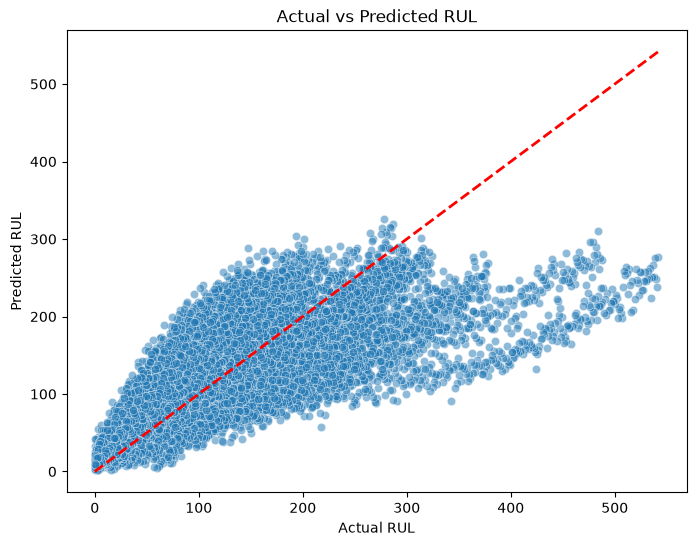

In [6]:
# Evaluate the Model
y_pred = model.predict(X_test_scaled, verbose=0).ravel()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('MAE:', round(mae, 4))
print('MSE:', round(mse, 4))
print('RMSE:', round(rmse, 4))
print('R2 Score:', round(r2, 4))

# Scatter plot of actual vs predicted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs Predicted RUL')
plt.xlabel('Actual RUL')
plt.ylabel('Predicted RUL')
plt.show()




## RNN and LSTM models

This notebook trains two recurrent models on sliding windows of engine cycles. Each model predicts one RUL value per timestep in the window (many-to-many sequence regression).

In [7]:
from pathlib import Path
base_dir = Path.cwd().resolve()
if not (base_dir / 'Data').exists():
    base_dir = base_dir.parent

path = (base_dir / 'Data' / 'Turbofan_Engine_Degradation_Dataset.csv').resolve()
df = pd.read_csv(path)

df = df.sort_values(['engine_id', 'cycle']).reset_index(drop=True)
df = df.drop_duplicates().copy()

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [col for col in numeric_cols if col not in ['engine_id', 'RUL']]

for col in feature_cols:
    df[col] = df[col].fillna(df[col].median())

print('Shape after cleaning:', df.shape)
print('Features used:', feature_cols)
df.head()

Shape after cleaning: (61249, 27)
Features used: ['cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670,320
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552,319
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213,318
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,...,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176,317
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,...,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754,316


In [8]:
WINDOW_SIZE = 30
TARGET_COL = 'RUL'


def make_sequence_windows(engine_df, feature_cols, window_size=WINDOW_SIZE):
    X_windows = []
    y_windows = []
    engine_windows = []
    cycle_windows = []
    short_engine_count = 0

    for engine_id, one_engine in engine_df.groupby('engine_id', sort=False):
        one_engine = one_engine.sort_values('cycle')
        X_values = one_engine[feature_cols].to_numpy(dtype=np.float32)
        y_values = one_engine[TARGET_COL].to_numpy(dtype=np.float32)
        cycle_values = one_engine['cycle'].to_numpy()

        if len(one_engine) < window_size:
            short_engine_count += 1
            continue

        for start in range(len(one_engine) - window_size + 1):
            end = start + window_size
            X_windows.append(X_values[start:end])
            y_windows.append(y_values[start:end, np.newaxis])
            engine_windows.append(np.full(window_size, engine_id))
            cycle_windows.append(cycle_values[start:end])

    if not X_windows:
        empty_metadata = np.empty((0, window_size), dtype=np.int32)
        return (
            np.empty((0, window_size, len(feature_cols)), dtype=np.float32),
            np.empty((0, window_size, 1), dtype=np.float32),
            empty_metadata,
            empty_metadata.copy(),
            short_engine_count,
        )

    return (
        np.asarray(X_windows, dtype=np.float32),
        np.asarray(y_windows, dtype=np.float32),
        np.asarray(engine_windows),
        np.asarray(cycle_windows),
        short_engine_count,
    )


engines = sorted(df['engine_id'].unique())
train_engines, temp_engines = train_test_split(engines, test_size=0.3, random_state=42)
val_engines, test_engines = train_test_split(temp_engines, test_size=0.5, random_state=42)

train_df = df[df['engine_id'].isin(train_engines)].copy()
val_df = df[df['engine_id'].isin(val_engines)].copy()
test_df = df[df['engine_id'].isin(test_engines)].copy()

scaler = StandardScaler()
scaler.fit(train_df[feature_cols].to_numpy())

train_df[feature_cols] = scaler.transform(train_df[feature_cols].to_numpy())
val_df[feature_cols] = scaler.transform(val_df[feature_cols].to_numpy())
test_df[feature_cols] = scaler.transform(test_df[feature_cols].to_numpy())

X_train, y_train, engine_train, cycle_train, train_short_engines = make_sequence_windows(train_df, feature_cols, WINDOW_SIZE)
X_val, y_val, engine_val, cycle_val, val_short_engines = make_sequence_windows(val_df, feature_cols, WINDOW_SIZE)
X_test, y_test, engine_test, cycle_test, test_short_engines = make_sequence_windows(test_df, feature_cols, WINDOW_SIZE)

print('Train engines:', train_df['engine_id'].nunique(), 'short engines dropped:', train_short_engines)
print('Validation engines:', val_df['engine_id'].nunique(), 'short engines dropped:', val_short_engines)
print('Test engines:', test_df['engine_id'].nunique(), 'short engines dropped:', test_short_engines)
print('Train shapes:', X_train.shape, y_train.shape, engine_train.shape, cycle_train.shape)
print('Validation shapes:', X_val.shape, y_val.shape, engine_val.shape, cycle_val.shape)
print('Test shapes:', X_test.shape, y_test.shape, engine_test.shape, cycle_test.shape)

assert X_train.shape[1:] == (WINDOW_SIZE, len(feature_cols))
assert y_train.shape[1:] == (WINDOW_SIZE, 1)
assert engine_train.shape == y_train.shape[:2] == cycle_train.shape
assert X_val.shape[1:] == (WINDOW_SIZE, len(feature_cols))
assert y_val.shape[1:] == (WINDOW_SIZE, 1)
assert engine_val.shape == y_val.shape[:2] == cycle_val.shape
assert X_test.shape[1:] == (WINDOW_SIZE, len(feature_cols))
assert y_test.shape[1:] == (WINDOW_SIZE, 1)
assert engine_test.shape == y_test.shape[:2] == cycle_test.shape


Train engines: 174 short engines dropped: 0
Validation engines: 37 short engines dropped: 0
Test engines: 38 short engines dropped: 0
Train shapes: (37788, 30, 25) (37788, 30, 1) (37788, 30) (37788, 30)
Validation shapes: (8029, 30, 25) (8029, 30, 1) (8029, 30) (8029, 30)
Test shapes: (8211, 30, 25) (8211, 30, 1) (8211, 30) (8211, 30)


In [9]:
def build_rnn_model(window_size, n_features):
    model = keras.Sequential([
        layers.Input(shape=(window_size, n_features)),
        layers.SimpleRNN(64, return_sequences=True, activation='tanh'),
        layers.Dropout(0.2),
        layers.SimpleRNN(32, return_sequences=True),
        layers.Dense(16, activation='relu'),
        layers.Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae', keras.metrics.RootMeanSquaredError(name='rmse')])
    return model


def build_lstm_model(window_size, n_features):
    model = keras.Sequential([
        layers.Input(shape=(window_size, n_features)),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.2),
        layers.LSTM(32, return_sequences=True),
        layers.Dense(16, activation='relu'),
        layers.Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae', keras.metrics.RootMeanSquaredError(name='rmse')])
    return model


rnn_model = build_rnn_model(WINDOW_SIZE, len(feature_cols))
lstm_model = build_lstm_model(WINDOW_SIZE, len(feature_cols))

rnn_model.summary()

try:
    keras.utils.plot_model(rnn_model, show_shapes=True, rankdir='TB', dpi=100)
except Exception as exc:
    print(f'Plot model skipped: {exc}')


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 30, 64)         │         5,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 30, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 30, 16)         │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 30, 1)          │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,409 (36.75 KB)

 Trainable params: 9,409 (36.75 KB)

 Non-trainable params: 0 (0.00 B)

You must install pydot (`pip install pydot`) for `plot_model` to work.


In [10]:
model_dir = base_dir / 'models'
model_dir.mkdir(parents=True, exist_ok=True)
rnn_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    ),
]
lstm_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    ),
]

history_rnn = rnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    verbose=1,
    callbacks=rnn_callbacks,
)

history_lstm = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    verbose=1,
    callbacks=lstm_callbacks,
)

print(f'Best RNN validation loss: {min(history_rnn.history["val_loss"]):.4f}')
print(f'Best LSTM validation loss: {min(history_lstm.history["val_loss"]):.4f}')


Epoch 1/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 11126.3672 - mae: 81.3764 - rmse: 105.4816 - val_loss: 6991.4219 - val_mae: 66.7069 - val_rmse: 83.6147
Epoch 2/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 4786.4072 - mae: 54.6573 - rmse: 69.1839 - val_loss: 4710.3320 - val_mae: 52.8614 - val_rmse: 68.6319
Epoch 3/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 3450.6033 - mae: 46.8679 - rmse: 58.7418 - val_loss: 3575.4546 - val_mae: 45.4029 - val_rmse: 59.7951
Epoch 4/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 2784.8757 - mae: 41.1412 - rmse: 52.7719 - val_loss: 3126.3831 - val_mae: 41.8332 - val_rmse: 55.9141
Epoch 5/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - loss: 2546.2502 - mae: 38.9503 - rmse: 50.4604 - val_loss: 2920.3936 - val_mae: 40.0602 - val_rmse: 54.0407
Epoch 6/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 2425.1404 - mae: 37.8250 - rmse: 49.2457 - val_loss: 2958.4817 - val_mae: 39.1271 - val_rmse: 54.3919
Epoch 7/20
591/591 ━

Metrics are calculated once per unique engine-cycle after averaging overlapping-window predictions.
MAE, MSE, and RMSE are better when lower; R2 is better when higher.


MAE        MSE     RMSE      R2
Model Split                                          
RNN   Train       33.9306  2075.3958  45.5565  0.7227
      Validation  37.1065  2709.9314  52.0570  0.6713
      Test        52.9137  5558.2612  74.5537  0.4691
LSTM  Train       32.9671  1988.6337  44.5941  0.7343
      Validation  36.5233  2647.6667  51.4555  0.6788
      Test        51.7446  5428.9531  73.6814  0.4815

Best RNN/LSTM model by validation RMSE: LSTM


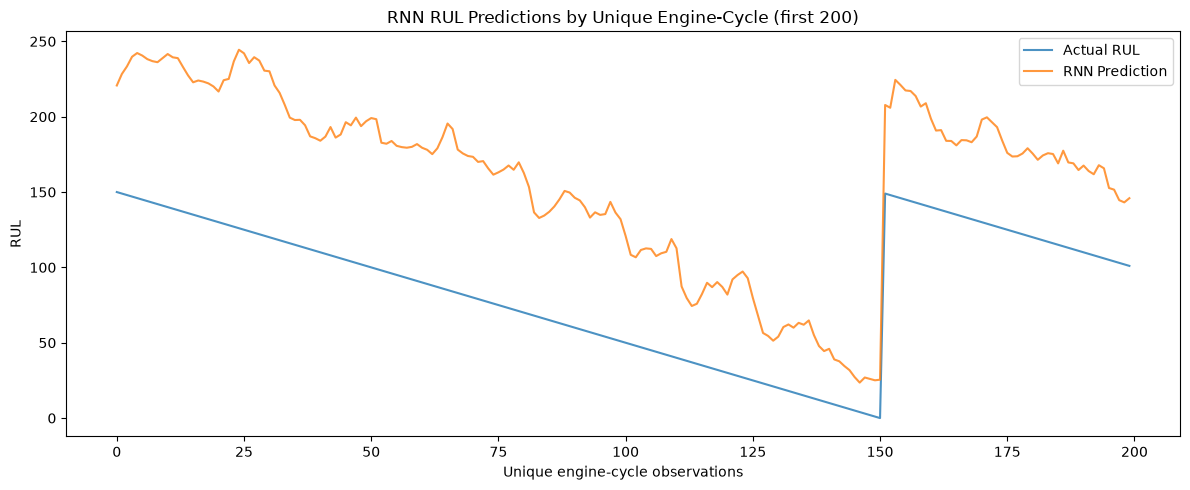

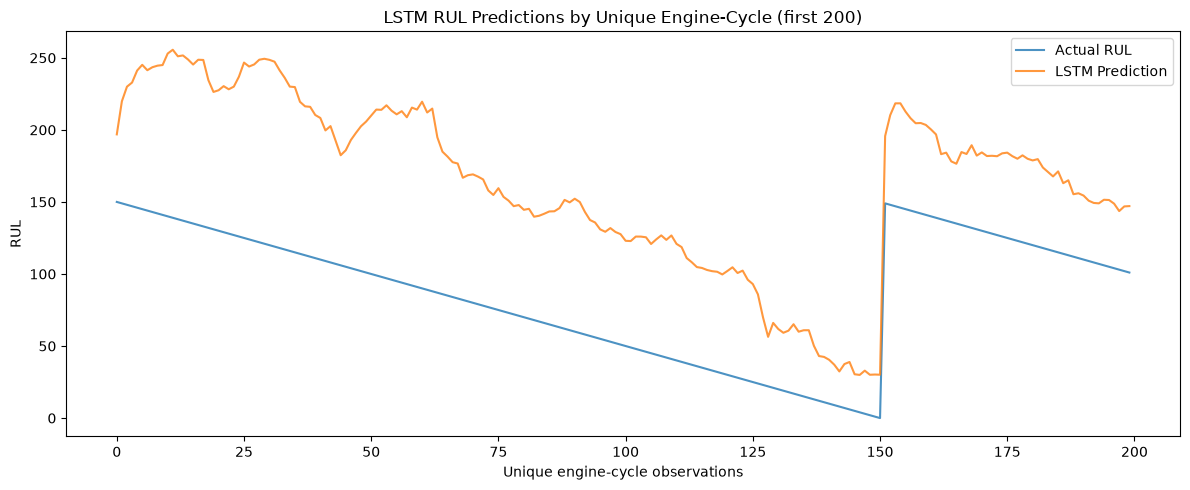

In [11]:
def evaluate_many_to_many(model, X, y, engine_ids, cycles):
    y_pred = model.predict(X, verbose=0).squeeze(axis=-1)
    y_true = y.squeeze(axis=-1)

    cycle_predictions = pd.DataFrame({
        'engine_id': engine_ids.reshape(-1),
        'cycle': cycles.reshape(-1),
        'actual_RUL': y_true.reshape(-1),
        'predicted_RUL': y_pred.reshape(-1),
    })
    cycle_predictions = (
        cycle_predictions
        .groupby(['engine_id', 'cycle'], as_index=False)
        .agg(actual_RUL=('actual_RUL', 'mean'), predicted_RUL=('predicted_RUL', 'mean'))
        .sort_values(['engine_id', 'cycle'])
        .reset_index(drop=True)
    )

    actual = cycle_predictions['actual_RUL']
    predicted = cycle_predictions['predicted_RUL']
    metrics = {
        'MAE': mean_absolute_error(actual, predicted),
        'MSE': mean_squared_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'R2': r2_score(actual, predicted),
    }
    return metrics, cycle_predictions


evaluation_sets = {
    'Train': (X_train, y_train, engine_train, cycle_train),
    'Validation': (X_val, y_val, engine_val, cycle_val),
    'Test': (X_test, y_test, engine_test, cycle_test),
}
models = {'RNN': rnn_model, 'LSTM': lstm_model}
metric_rows = []
predictions = {}

for model_name, model in models.items():
    for split_name, (X_split, y_split, engine_ids, cycles) in evaluation_sets.items():
        metrics, cycle_predictions = evaluate_many_to_many(
            model, X_split, y_split, engine_ids, cycles
        )
        metric_rows.append({'Model': model_name, 'Split': split_name, **metrics})
        predictions[(model_name, split_name)] = cycle_predictions

metrics_df = pd.DataFrame(metric_rows).set_index(['Model', 'Split'])
print('Metrics are calculated once per unique engine-cycle after averaging overlapping-window predictions.')
print('MAE, MSE, and RMSE are better when lower; R2 is better when higher.')
display(metrics_df.round(4))

best_validation_model = metrics_df.xs('Validation', level='Split')['RMSE'].idxmin()
print(f'Best RNN/LSTM model by validation RMSE: {best_validation_model}')

for model_name in models:
    cycle_predictions = predictions[(model_name, 'Test')]
    plt.figure(figsize=(12, 5))
    plt.plot(cycle_predictions['actual_RUL'].to_numpy()[:200], label='Actual RUL', alpha=0.8)
    plt.plot(cycle_predictions['predicted_RUL'].to_numpy()[:200], label=f'{model_name} Prediction', alpha=0.8)
    plt.title(f'{model_name} RUL Predictions by Unique Engine-Cycle (first 200)')
    plt.xlabel('Unique engine-cycle observations')
    plt.ylabel('RUL')
    plt.legend()
    plt.tight_layout()
    plt.show()


## Save only the ANN regression model

The ANN, RNN, and LSTM can all be trained and evaluated, but only the ANN is saved to the `models` folder. Its feature scaler and column metadata are saved alongside it so the model can be used for future predictions. RNN and LSTM use early stopping and remain in memory only.


In [12]:
from pathlib import Path
import json
import joblib

models_dir = base_dir / "models"
ann_checkpoint_path = models_dir / "ann_best.keras"
ann_preprocessing_path = models_dir / "ann_preprocessing.joblib"
required_artifacts = (ann_checkpoint_path, ann_preprocessing_path)
missing_artifacts = [path for path in required_artifacts if not path.is_file()]
if missing_artifacts:
    missing_list = "\n".join(str(path) for path in missing_artifacts)
    raise FileNotFoundError(
        "Train the ANN, RNN, and LSTM first. Missing required artifacts:\n" + missing_list
    )

ann_preprocessing = joblib.load(ann_preprocessing_path)
ann_scaler = ann_preprocessing["scaler"]
ann_feature_columns = ann_preprocessing["feature_columns"]
if set(ann_feature_columns) != set(feature_cols):
    raise ValueError(
        "ANN and RNN/LSTM use different feature columns; "
        "retrain the ANN with the current dataset before comparing."
    )

# Reconstruct raw validation features and align their order to the ANN scaler.
val_flat_scaled = X_val.reshape(-1, X_val.shape[-1])
val_flat_raw = scaler.inverse_transform(val_flat_scaled)
ann_feature_indices = [feature_cols.index(column) for column in ann_feature_columns]
ann_val_features = ann_scaler.transform(val_flat_raw[:, ann_feature_indices])
ann_model = keras.models.load_model(ann_checkpoint_path)
ann_val_predictions = ann_model.predict(ann_val_features, batch_size=256, verbose=0).reshape(-1)

ann_validation_cycles = pd.DataFrame({
    "engine_id": engine_val.reshape(-1),
    "cycle": cycle_val.reshape(-1),
    "actual_RUL": y_val.reshape(-1),
    "predicted_RUL": ann_val_predictions,
})
ann_validation_cycles = (
    ann_validation_cycles
    .groupby(["engine_id", "cycle"], as_index=False)
    .agg(actual_RUL=("actual_RUL", "mean"), predicted_RUL=("predicted_RUL", "mean"))
)

validation_predictions = {
    "ANN": ann_validation_cycles,
    "RNN": predictions[("RNN", "Validation")],
    "LSTM": predictions[("LSTM", "Validation")],
}
common_validation_cycles = (
    validation_predictions["ANN"][['engine_id', 'cycle']]
    .merge(validation_predictions["RNN"][['engine_id', 'cycle']], on=['engine_id', 'cycle'])
    .merge(validation_predictions["LSTM"][['engine_id', 'cycle']], on=['engine_id', 'cycle'])
)
if common_validation_cycles.empty:
    raise ValueError("ANN, RNN, and LSTM have no common validation engine-cycles to compare.")

validation_rmse = {}
for model_name, cycle_predictions in validation_predictions.items():
    aligned_predictions = common_validation_cycles.merge(
        cycle_predictions, on=['engine_id', 'cycle'], validate='one_to_one'
    )
    validation_rmse[model_name] = float(np.sqrt(mean_squared_error(
        aligned_predictions['actual_RUL'], aligned_predictions['predicted_RUL']
    )))
print("Common held-out validation RMSE (lower is better):")
for model_name, rmse in validation_rmse.items():
    print(f"{model_name}: {rmse:.4f}")

# Save the ANN and its preprocessing, preserving other project models.
ann_model_path = models_dir / "ann_best.keras"
ann_model.save(ann_model_path)
ann_preprocessing_path = models_dir / "ann_preprocessing.joblib"
joblib.dump(
    {"scaler": ann_scaler, "feature_columns": list(ann_feature_columns)},
    ann_preprocessing_path,
)

print(f"Saved ANN regression model: {ann_model_path}")
print(f"Saved ANN preprocessing: {ann_preprocessing_path}")


c:\Users\nihaa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Common held-out validation RMSE (lower is better):
ANN: 51.4159
RNN: 52.0570
LSTM: 51.4555
Saved ANN regression model: D:\Guvi\Ferro Vision\models\ann_best.keras
Saved ANN preprocessing: D:\Guvi\Ferro Vision\models\ann_preprocessing.joblib


## Final held-out test evaluation

Evaluate ANN, RNN, and LSTM on the same unique test engine-cycles. Overlapping sequence predictions are averaged per engine-cycle. Only the ANN is saved to the `models` folder. MAE, MSE, and RMSE are better when lower; R² is better when higher.

In [13]:
# Reconstruct the raw test features and apply the ANN's saved preprocessing.
test_flat_scaled = X_test.reshape(-1, X_test.shape[-1])
test_flat_raw = scaler.inverse_transform(test_flat_scaled)
ann_test_features = ann_scaler.transform(pd.DataFrame(
    test_flat_raw[:, ann_feature_indices], columns=ann_feature_columns
))
ann_test_predictions = ann_model.predict(ann_test_features, batch_size=256, verbose=0).reshape(-1)

ann_test_cycles = pd.DataFrame({
    "engine_id": engine_test.reshape(-1),
    "cycle": cycle_test.reshape(-1),
    "actual_RUL": y_test.reshape(-1),
    "predicted_RUL": ann_test_predictions,
})
ann_test_cycles = (
    ann_test_cycles
    .groupby(["engine_id", "cycle"], as_index=False)
    .agg(actual_RUL=("actual_RUL", "mean"), predicted_RUL=("predicted_RUL", "mean"))
)

test_predictions = {
    "ANN": ann_test_cycles,
    "RNN": predictions[("RNN", "Test")],
    "LSTM": predictions[("LSTM", "Test")],
}
common_test_cycles = (
    test_predictions["ANN"][["engine_id", "cycle"]]
    .merge(test_predictions["RNN"][["engine_id", "cycle"]], on=["engine_id", "cycle"])
    .merge(test_predictions["LSTM"][["engine_id", "cycle"]], on=["engine_id", "cycle"])
)
if common_test_cycles.empty:
    raise ValueError("ANN, RNN, and LSTM have no common test engine-cycles to evaluate.")

test_metric_rows = []
for model_name, cycle_predictions in test_predictions.items():
    aligned = common_test_cycles.merge(
        cycle_predictions, on=["engine_id", "cycle"], validate="one_to_one"
    )
    actual = aligned["actual_RUL"]
    predicted = aligned["predicted_RUL"]
    test_metric_rows.append({
        "Model": model_name,
        "Test engine-cycles": len(aligned),
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    })

test_metrics_df = pd.DataFrame(test_metric_rows).set_index("Model")
print("Final test metrics on the same unique held-out engine-cycles:")
display(test_metrics_df.round(4))

Final test metrics on the same unique held-out engine-cycles:


,Test engine-cycles,MAE,MSE,RMSE,R2
Model,,,,,
ANN,9313,52.5417,5304.5464,72.8323,0.4934
RNN,9313,52.9137,5558.2612,74.5537,0.4691
LSTM,9313,51.7446,5428.9531,73.6814,0.4815
